# Compare Shots

Several shots side by side. List the shot files in `SHOTS` and run all cells. Every shot is put on the same "time into shot" axis (t = 0 is where pressure first lifts off its resting level), using the same measurements as `shot_analysis.ipynb` (shared code in `shotlib.py`). Setup and tasting notes come from `data/shot_notes.csv`.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from shotlib import analyse, comparison_table, TARGET_BAR, THRESHOLD_BAR

SHOTS = ["shot_010", "shot_011", "shot_012"]
COLOURS = ["tab:blue", "tab:orange", "tab:green", "tab:red", "tab:purple", "tab:brown"]

results = {name: analyse(f"data/{name}.csv") for name in SHOTS}

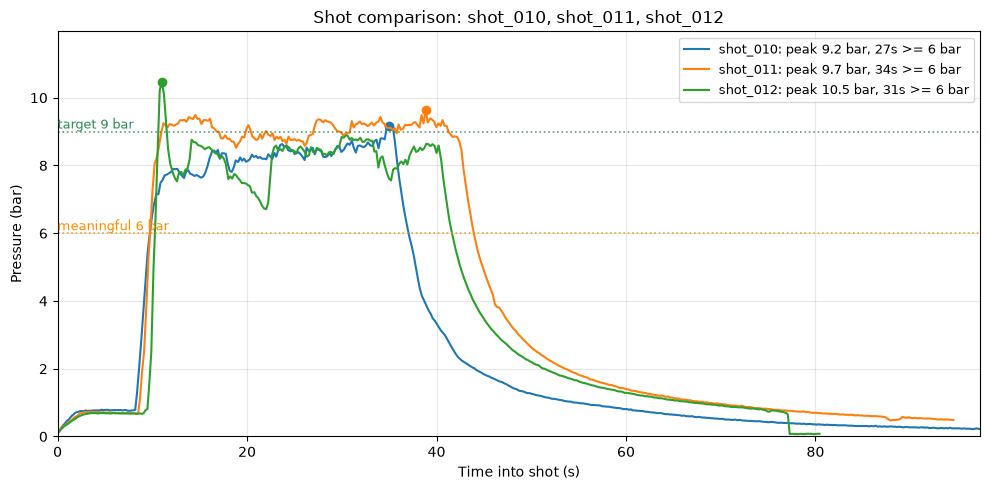

In [2]:
# all shots on one chart
fig, ax = plt.subplots(figsize=(10, 5))
for (name, (df, m)), colour in zip(results.items(), COLOURS):
    ax.plot(df["t"], df["bar"], color=colour, linewidth=1.5,
            label=f"{name}: peak {m['peak_bar']:.1f} bar, {m['meaningful_s']:.0f}s >= {THRESHOLD_BAR} bar")
    ax.plot(m["peak_t"], m["peak_bar"], "o", color=colour)
ax.axhline(TARGET_BAR, color="seagreen", linestyle=":", linewidth=1.2, alpha=0.8)
ax.text(0, TARGET_BAR, f"target {TARGET_BAR:.0f} bar ", va="bottom", ha="left", color="seagreen", fontsize=9)
ax.axhline(THRESHOLD_BAR, color="darkorange", linestyle=":", linewidth=1.2, alpha=0.8)
ax.text(0, THRESHOLD_BAR, f"meaningful {THRESHOLD_BAR:.0f} bar ", va="bottom", ha="left", color="darkorange", fontsize=9)
ax.set_xlabel("Time into shot (s)")
ax.set_ylabel("Pressure (bar)")
ax.set_title("Shot comparison: " + ", ".join(SHOTS))
ax.set_xlim(0, max(df["t"].max() for df, _ in results.values()))
ax.set_ylim(0, max(TARGET_BAR, *(m["peak_bar"] for _, m in results.values())) + 1.5)
ax.legend(loc="upper right", fontsize=9)
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig("figures/compare_shots.png", dpi=150)
plt.show()

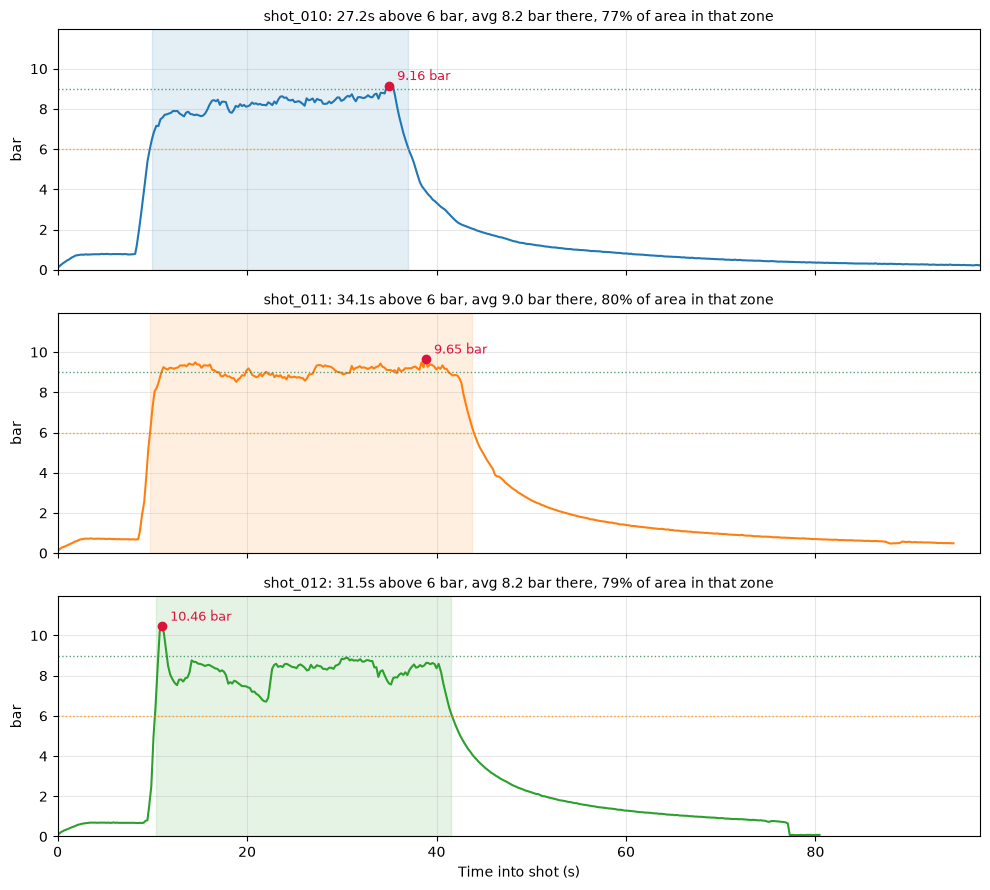

In [3]:
# one panel per shot, same axes, so each can be judged on its own
x_max = max(df["t"].max() for df, _ in results.values())
y_max = max(TARGET_BAR, *(m["peak_bar"] for _, m in results.values())) + 1.5
fig, axes = plt.subplots(len(results), 1, figsize=(10, 3 * len(results)), sharex=True, sharey=True)
for ax, (name, (df, m)), colour in zip(axes, results.items(), COLOURS):
    ax.plot(df["t"], df["bar"], color=colour, linewidth=1.5)
    ax.axvspan(m["extraction_start"], m["extraction_end"], color=colour, alpha=0.12)
    ax.axhline(TARGET_BAR, color="seagreen", linestyle=":", linewidth=1, alpha=0.8)
    ax.axhline(THRESHOLD_BAR, color="darkorange", linestyle=":", linewidth=1, alpha=0.8)
    ax.plot(m["peak_t"], m["peak_bar"], "o", color="crimson")
    ax.annotate(f"{m['peak_bar']:.2f} bar", xy=(m["peak_t"], m["peak_bar"]),
                xytext=(6, 4), textcoords="offset points", color="crimson", fontsize=9)
    ax.set_title(f"{name}: {m['meaningful_s']:.1f}s above {THRESHOLD_BAR} bar, "
                 f"avg {m['zone_mean_bar']:.1f} bar there, "
                 f"{m['area_extraction'] / m['area_total']:.0%} of area in that zone", fontsize=10)
    ax.set_ylabel("bar")
    ax.grid(alpha=0.3)
axes[-1].set_xlabel("Time into shot (s)")
axes[0].set_xlim(0, x_max)
axes[0].set_ylim(0, y_max)
fig.tight_layout()
fig.savefig("figures/compare_shots_panels.png", dpi=150)
plt.show()

In [4]:
comparison_table({name: m for name, (_, m) in results.items()})

,shot_010,shot_011,shot_012
shot timer: pre-infusion + extraction (s),37.2,43.9,41.8
pre-infusion (s),8.4,8.7,9.7
pre-infusion pressure (bar),0.69,0.62,0.60
extraction (s),28.8,35.3,32.1
dripping (s),60.2,50.6,38.6
"ramp, 1 to 6 bar (s)",1.6,1.1,0.7
"meaningful extraction, >= 6 bar (s)",27.2,34.1,31.5
average pressure in that zone (bar),8.18,8.96,8.20
peak (bar),9.16,9.65,10.46
peak at (s into shot),35.0,38.9,11.0


In [5]:
# setup and tasting notes for these shots (blank = not recorded yet)
notes = pd.read_csv("data/shot_notes.csv").set_index("shot")
notes.reindex(SHOTS).fillna("")

,date,beans,roast,freshness,grind_setting,dose_g,yield_g,basket,comments
shot,,,,,,,,,
shot_010,2026-10-24,Lidl (£3),very dark,fresh,3.0,9.0,,small,"very nice: balanced, no sourness, no bitternes..."
shot_011,2026-10-25,Lidl,very dark,fresh,2.0,9.0,35.0,small,Best shot so far. No taste notes identified
shot_012,2026-10-25,Lidl,very dark,fresh,2.0,9.0,27.0,small,Bitter - slightly burnt. Grinder was stuck wit...
